In [1]:
#-*- coding: utf-8 -*- 

# 对数据进行基本的探索
# 返回缺失值个数以及最大最小值

import pandas as pd

datafile= 'C:/Users/lenovo/Desktop/air_data/air_data.csv'  # 航空原始数据,第一行为属性标签
resultfile = 'C:/Users/lenovo/Desktop/air_data/air_data_result.csv'  # 数据探索结果表

# 读取原始数据，指定UTF-8编码（需要用文本编辑器将数据装换为UTF-8编码）
data = pd.read_csv(datafile, encoding = 'utf-8')

# 包括对数据的基本描述，percentiles参数是指定计算多少的分位数表（如1/4分位数、中位数等）
explore = data.describe(percentiles = [], include = 'all').T  # T是转置，转置后更方便查阅
explore['null'] = len(data)-explore['count']  # describe()函数自动计算非空值数，需要手动计算空值数

explore = explore[['null', 'max', 'min']]
explore.columns = [u'空值数', u'最大值', u'最小值']  # 表头重命名
'''
这里只选取部分探索结果。
describe()函数自动计算的字段有count（非空值数）、unique（唯一值数）、top（频数最高者）、
freq（最高频数）、mean（平均值）、std（方差）、min（最小值）、50%（中位数）、max（最大值）
'''

explore.to_csv(resultfile)  # 导出结果
explore

,空值数,最大值,最小值
MEMBER_NO,0.0,62988.0,1.0
FFP_DATE,0,NaN,NaN
FIRST_FLIGHT_DATE,0,NaN,NaN
GENDER,3,NaN,NaN
FFP_TIER,0.0,6.0,4.0
WORK_CITY,2269,NaN,NaN
WORK_PROVINCE,3248,NaN,NaN
WORK_COUNTRY,26,NaN,NaN
AGE,420.0,110.0,6.0
LOAD_TIME,0,NaN,NaN


In [2]:
# 客户信息类别
# 提取会员入会年份
from datetime import datetime
ffp = data['FFP_DATE'].apply(lambda x:datetime.strptime(x,'%Y/%m/%d'))
ffp_year = ffp.map(lambda x : x.year)
ffp.head()

0   2006-11-02
1   2007-02-19
2   2007-02-01
3   2008-08-22
4   2009-04-10
Name: FFP_DATE, dtype: datetime64[ns]

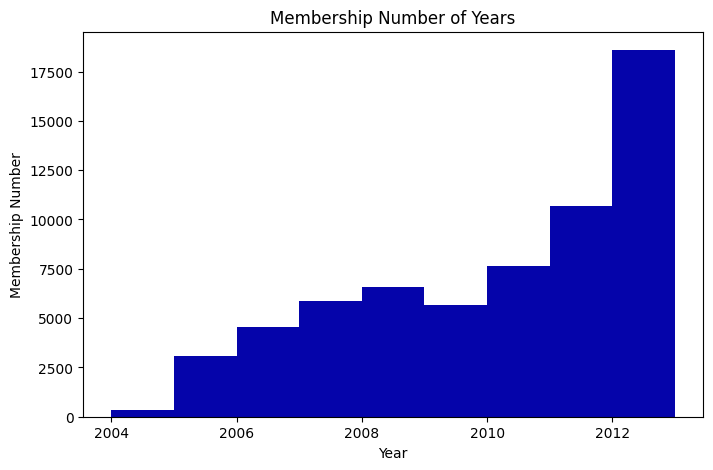

In [3]:
# 绘制各年份会员入会人数直方图
import matplotlib.pyplot as plt
fig = plt.figure(figsize = (8 ,5))  # 设置画布大小
plt.rcParams['axes.unicode_minus'] = False
plt.hist(ffp_year, bins='auto', color='#0504aa')
plt.xlabel('Year')
plt.ylabel('Membership Number')
plt.title('Membership Number of Years')
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_10984\2004867121.py:2: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  male = pd.value_counts(data['GENDER'])['男']
C:\Users\lenovo\AppData\Local\Temp\ipykernel_10984\2004867121.py:3: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  female = pd.value_counts(data['GENDER'])['女']


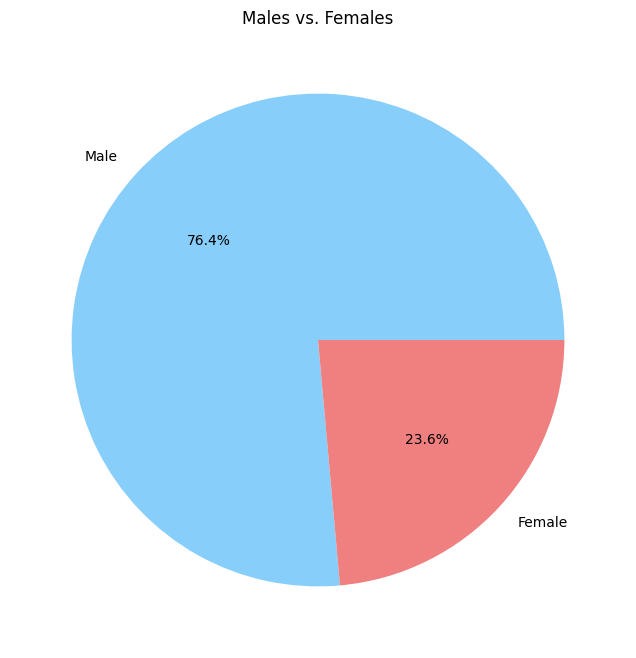

In [4]:
# 绘制会员不同性别人数的饼图
male = pd.value_counts(data['GENDER'])['男']
female = pd.value_counts(data['GENDER'])['女']
# 绘制会员性别比例饼图
fig = plt.figure(figsize = (8 ,8))  # 设置画布大小
plt.pie([ male, female], labels=['Male','Female'], colors=['lightskyblue', 'lightcoral'],
       autopct='%1.1f%%')
plt.title('Males vs. Females')
plt.show()

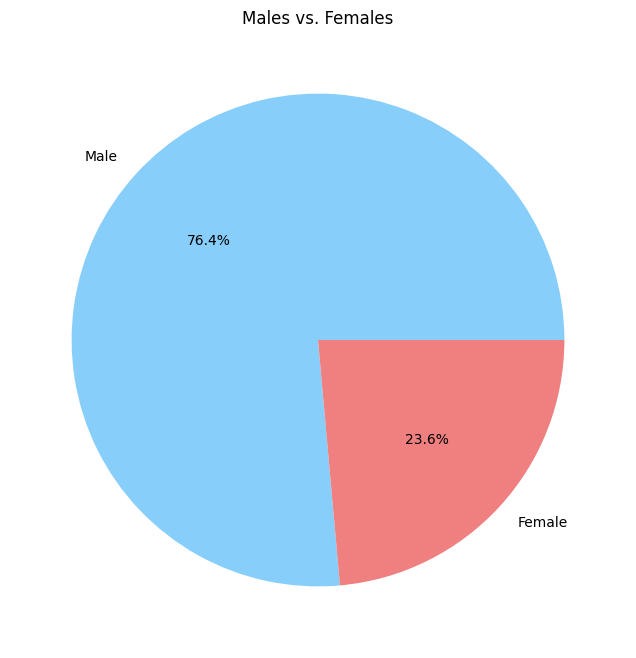

In [5]:
# 绘制会员不同性别人数的饼图
# 使用推荐的value_counts方法
gender_counts = data['GENDER'].value_counts()
male = gender_counts.get('男', 0)  # 使用get方法避免KeyError
female = gender_counts.get('女', 0)

# 绘制会员性别比例饼图
fig = plt.figure(figsize = (8 ,8))  # 设置画布大小
plt.pie([ male, female], labels=['Male','Female'], colors=['lightskyblue', 'lightcoral'],
       autopct='%1.1f%%')
plt.title('Males vs. Females')
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_10984\2381904450.py:2: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  lv_four = pd.value_counts(data['FFP_TIER'])[4]
C:\Users\lenovo\AppData\Local\Temp\ipykernel_10984\2381904450.py:3: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  lv_five = pd.value_counts(data['FFP_TIER'])[5]
C:\Users\lenovo\AppData\Local\Temp\ipykernel_10984\2381904450.py:4: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  lv_six = pd.value_counts(data['FFP_TIER'])[6]


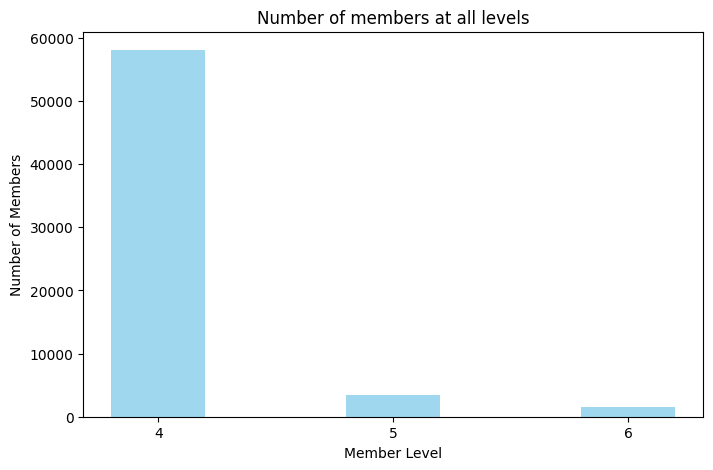

In [6]:
# 提取不同级别会员的人数
lv_four = pd.value_counts(data['FFP_TIER'])[4]
lv_five = pd.value_counts(data['FFP_TIER'])[5]
lv_six = pd.value_counts(data['FFP_TIER'])[6]
# 绘制会员各级别人数条形图
fig = plt.figure(figsize = (8 ,5))  # 设置画布大小
plt.bar(range(3), height=[lv_four,lv_five,lv_six], width=0.4, alpha=0.8, color='skyblue')
plt.xticks([index for index in range(3)], ['4','5','6'])
plt.xlabel('Member Level')
plt.ylabel('Number of Members')
plt.title('Number of members at all levels')
plt.show()

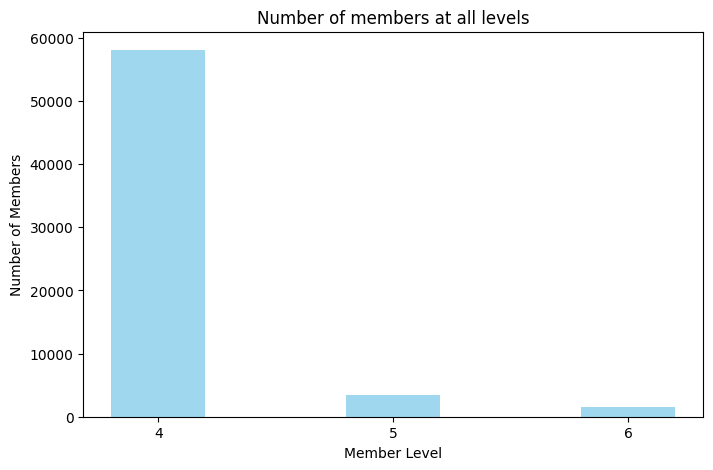

In [7]:
# 提取不同级别会员的人数
# 使用推荐的value_counts方法
tier_counts = data['FFP_TIER'].value_counts()
lv_four = tier_counts.get(4, 0)
lv_five = tier_counts.get(5, 0)
lv_six = tier_counts.get(6, 0)
# 绘制会员各级别人数条形图
fig = plt.figure(figsize = (8 ,5))  # 设置画布大小
plt.bar(range(3), height=[lv_four,lv_five,lv_six], width=0.4, alpha=0.8, color='skyblue')
plt.xticks([index for index in range(3)], ['4','5','6'])
plt.xlabel('Member Level')
plt.ylabel('Number of Members')
plt.title('Number of members at all levels')
plt.show()

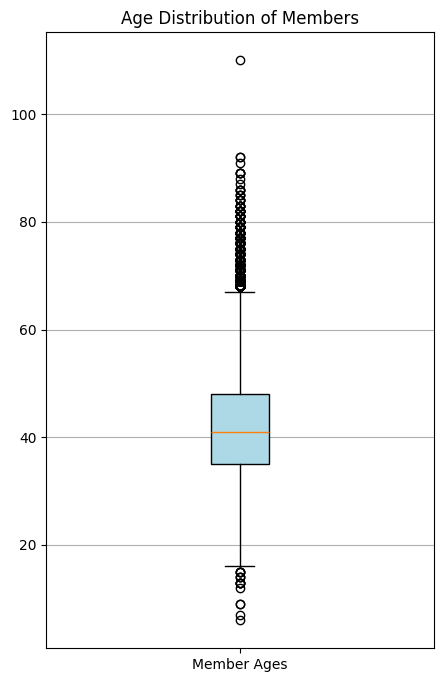

In [8]:
# 提取会员年龄
age = data['AGE'].dropna()
age = age.astype('int64')

# 绘制会员年龄分布箱型图
fig = plt.figure(figsize=(5, 8))
plt.boxplot(age, 
            patch_artist=True,
            tick_labels=['Member Ages'],  # 使用新的参数名
            boxprops={'facecolor': 'lightblue'})  # 设置填充颜色
plt.title('Age Distribution of Members')
plt.grid(axis='y')
plt.show()

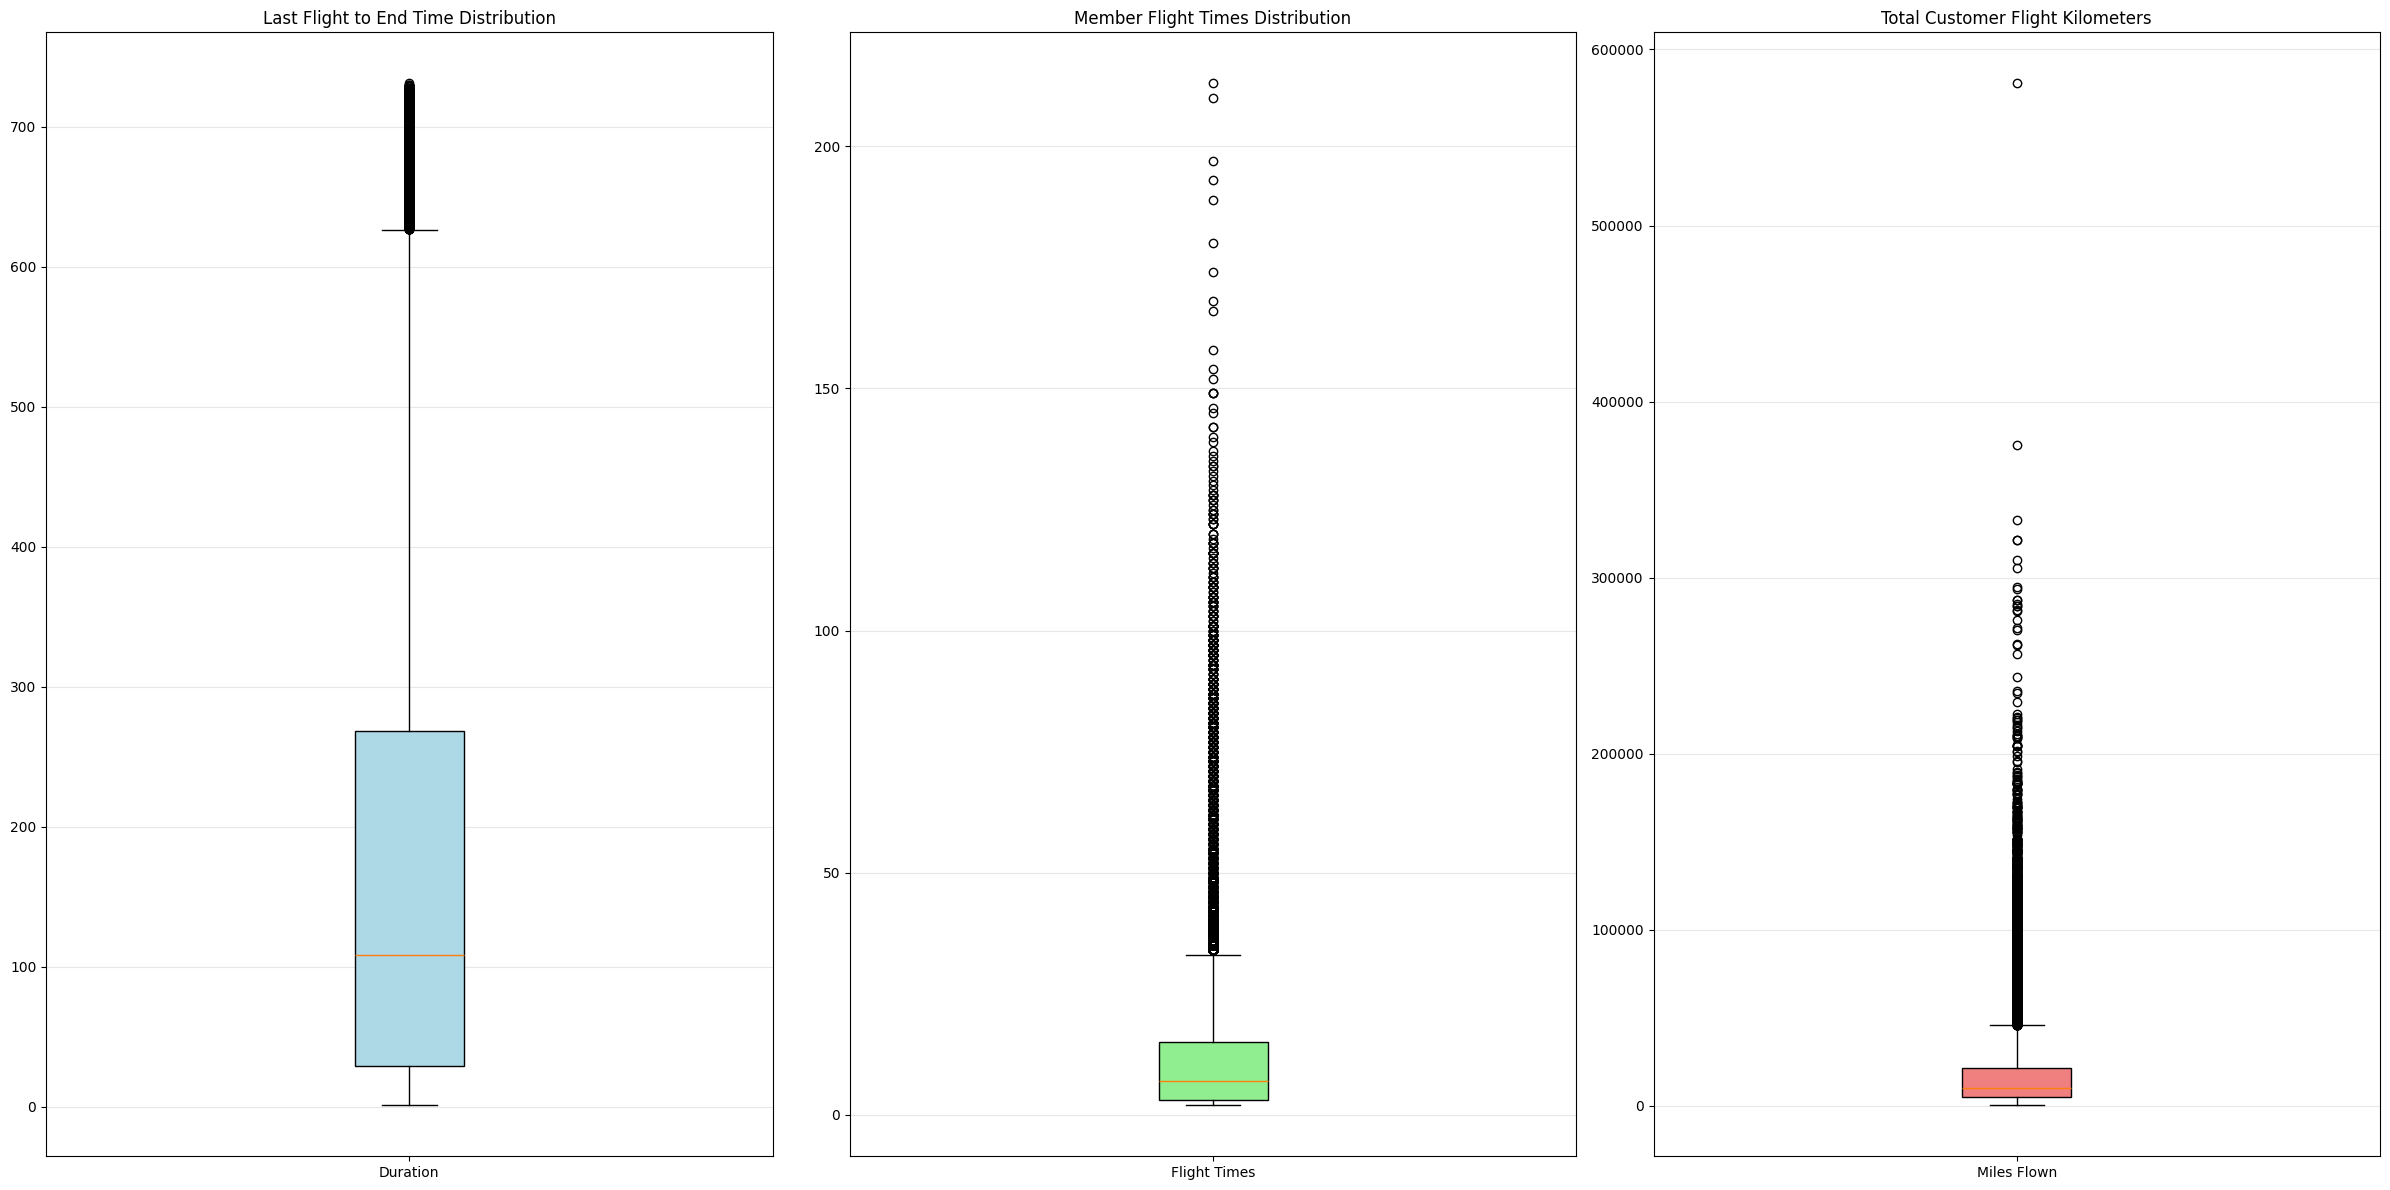

In [9]:
# 乘机信息类别
lte = data['LAST_TO_END']
fc = data['FLIGHT_COUNT']
sks = data['SEG_KM_SUM']

# 绘制三个箱线图的组合图表
fig = plt.figure(figsize=(24, 12))

# 绘制最后乘机至结束时长箱线图
ax1 = plt.subplot(1, 3, 1)
ax1.boxplot(lte.dropna(), 
            patch_artist=True,
            tick_labels=['Duration'],  # 使用新的参数名
            boxprops={'facecolor': 'lightblue'})
ax1.set_title('Last Flight to End Time Distribution')
ax1.grid(axis='y', alpha=0.3)

# 绘制客户飞行次数箱线图
ax2 = plt.subplot(1, 3, 2)
ax2.boxplot(fc.dropna(), 
            patch_artist=True,
            tick_labels=['Flight Times'],  # 使用新的参数名
            boxprops={'facecolor': 'lightgreen'})
ax2.set_title('Member Flight Times Distribution')
ax2.grid(axis='y', alpha=0.3)

# 绘制客户总飞行公里数箱线图
ax3 = plt.subplot(1, 3, 3)
ax3.boxplot(sks.dropna(), 
            patch_artist=True,
            tick_labels=['Miles Flown'],  # 使用新的参数名
            boxprops={'facecolor': 'lightcoral'})
ax3.set_title('Total Customer Flight Kilometers')
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

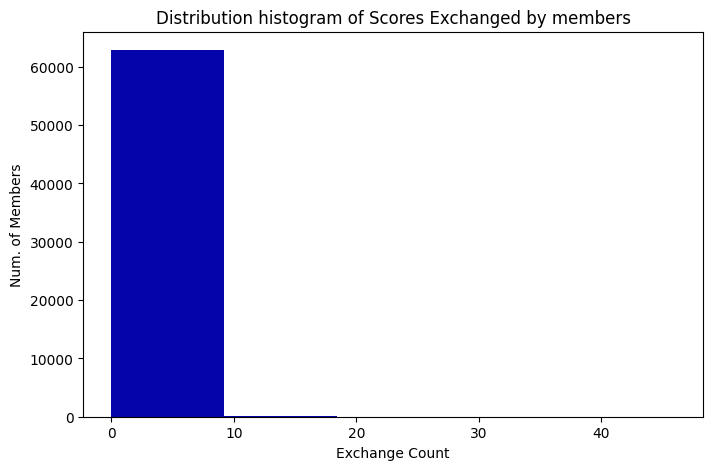

In [10]:
# 积分信息类别
# 提取会员积分兑换次数
ec = data['EXCHANGE_COUNT']
# 绘制会员兑换积分次数直方图
fig = plt.figure(figsize = (8 ,5))  # 设置画布大小
plt.hist(ec, bins=5, color='#0504aa')
plt.xlabel('Exchange Count')
plt.ylabel('Num. of Members')
plt.title('Distribution histogram of Scores Exchanged by members')
plt.show()

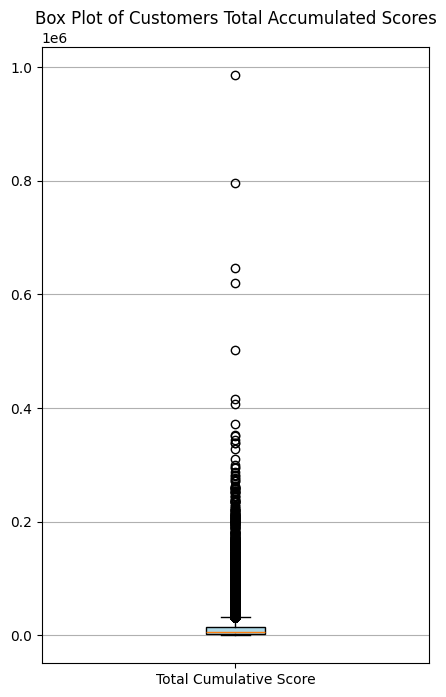

In [11]:
# 提取会员总累计积分
ps = data['Points_Sum']
# 绘制会员总累计积分箱线图
fig = plt.figure(figsize=(5, 8))
plt.boxplot(ps.dropna(), 
            patch_artist=True,
            tick_labels=['Total Cumulative Score'],  # 使用新的参数名
            boxprops={'facecolor': 'lightblue'})  # 设置填充颜色
plt.title('Box Plot of Customers Total Accumulated Scores')
# 显示y坐标轴的底线
plt.grid(axis='y')
plt.show()

In [12]:
import warnings
warnings.filterwarnings("ignore")
# 提取属性并合并为新数据集
data_corr = data[['FFP_TIER','FLIGHT_COUNT','LAST_TO_END',
                  'SEG_KM_SUM','EXCHANGE_COUNT','Points_Sum']]
age1 = data['AGE'].fillna(0)
data_corr['AGE'] = age1.astype('int64')
data_corr['ffp_year'] = ffp_year
data_corr.head()

,FFP_TIER,FLIGHT_COUNT,LAST_TO_END,SEG_KM_SUM,EXCHANGE_COUNT,Points_Sum,AGE,ffp_year
0,6,210,1,580717,34,619760,31,2006
1,6,140,7,293678,29,415768,42,2007
2,6,135,11,283712,20,406361,40,2007
3,5,23,97,281336,11,372204,64,2008
4,6,152,5,309928,27,338813,48,2009


In [13]:
# 计算相关性矩阵
dt_corr = data_corr.corr(method = 'pearson')
print('相关性矩阵为：\n')
dt_corr

相关性矩阵为：



,FFP_TIER,FLIGHT_COUNT,LAST_TO_END,SEG_KM_SUM,EXCHANGE_COUNT,Points_Sum,AGE,ffp_year
FFP_TIER,1.000000,0.582447,-0.206313,0.522350,0.342355,0.559249,0.076245,-0.116510
FLIGHT_COUNT,0.582447,1.000000,-0.404999,0.850411,0.502501,0.747092,0.075309,-0.188181
LAST_TO_END,-0.206313,-0.404999,1.000000,-0.369509,-0.169717,-0.292027,-0.027654,0.117913
SEG_KM_SUM,0.522350,0.850411,-0.369509,1.000000,0.507819,0.853014,0.087285,-0.171508
EXCHANGE_COUNT,0.342355,0.502501,-0.169717,0.507819,1.000000,0.578581,0.032760,-0.216610
Points_Sum,0.559249,0.747092,-0.292027,0.853014,0.578581,1.000000,0.074887,-0.163431
AGE,0.076245,0.075309,-0.027654,0.087285,0.032760,0.074887,1.000000,-0.242579
ffp_year,-0.116510,-0.188181,0.117913,-0.171508,-0.216610,-0.163431,-0.242579,1.000000


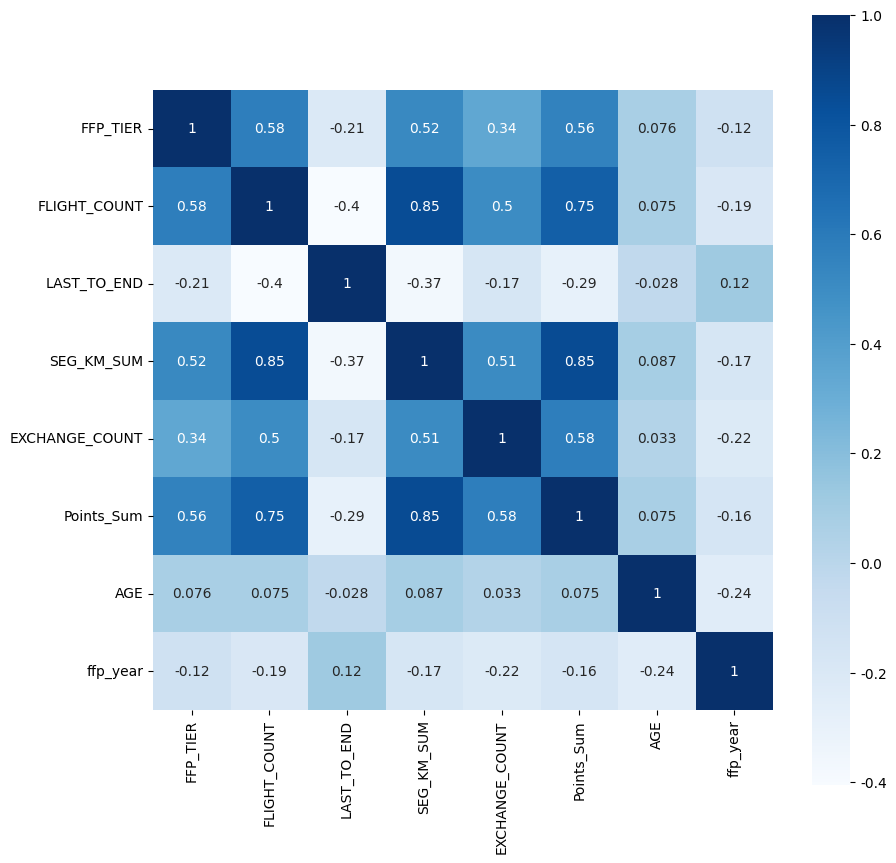

In [14]:
# 绘制热力图
import matplotlib.pyplot as plt
import seaborn as sns
plt.subplots(figsize=(10, 10)) # 设置画面大小 
sns.heatmap(dt_corr, annot=True, vmax=1, square=True, cmap='Blues') 
plt.show()

In [15]:
# 处理缺失值与异常值
import numpy as np
import pandas as pd

# 航空原始数据路径
datafile = 'C:/Users/lenovo/Desktop/air_data/air_data.csv'
# 数据清洗后保存的文件路径
cleanedfile = 'C:/Users/lenovo/Desktop/air_data/cleanedfile.csv'

# 读取数据
airline_data = pd.read_csv(datafile,encoding = 'utf-8')
print('原始数据的形状为:',airline_data.shape)

原始数据的形状为: (62988, 44)


In [16]:
# 去除票价为空的记录
airline_notnull = airline_data.loc[airline_data['SUM_YR_1'].notnull() & 
                                   airline_data['SUM_YR_2'].notnull(),:]
print('删除缺失记录后数据的形状为:',airline_notnull.shape)

删除缺失记录后数据的形状为: (62299, 44)


In [17]:
# 只保留票价非零的，或者平均折扣率不为0且总飞行公里数大于0的记录。
index1 = airline_notnull['SUM_YR_1'] != 0
index2 = airline_notnull['SUM_YR_2'] != 0
index3 = (airline_notnull['SEG_KM_SUM']> 0) & (airline_notnull['avg_discount'] != 0)
# 去除年龄大于100的记录
index4 = airline_notnull['AGE'] > 100
airline = airline_notnull[(index1 | index2) & index3 & ~index4]
print('数据清洗后数据的形状为:',airline.shape)

airline.to_csv(cleanedfile)  # 保存清洗后的数据

数据清洗后数据的形状为: (62043, 44)


In [18]:
# 属性选择、构造与数据标准化
import pandas as pd
import numpy as np

# 读取数据清洗后的数据
cleanedfile = 'C:/Users/lenovo/Desktop/air_data/cleanedfile.csv'  # 数据清洗后保存的文件路径
airline = pd.read_csv(cleanedfile, encoding = 'utf-8')
# 选取需求属性
airline_selection = airline[['FFP_DATE','LOAD_TIME','LAST_TO_END','FLIGHT_COUNT','SEG_KM_SUM','avg_discount']]
airline_selection.head()

,FFP_DATE,LOAD_TIME,LAST_TO_END,FLIGHT_COUNT,SEG_KM_SUM,avg_discount
0,2006/11/2,2014/3/31,1,210,580717,0.961639
1,2007/2/19,2014/3/31,7,140,293678,1.252314
2,2007/2/1,2014/3/31,11,135,283712,1.254676
3,2008/8/22,2014/3/31,97,23,281336,1.090870
4,2009/4/10,2014/3/31,5,152,309928,0.970658


In [19]:
# 构造属性L
L = pd.to_datetime(airline_selection['LOAD_TIME']) - pd.to_datetime(airline_selection['FFP_DATE'])
L = L.astype('str').str.split().str[0]
L = L.astype('int')/30

# 合并属性
airline_features = pd.concat([L,airline_selection.iloc[:,2:]],axis = 1)
airline_features.columns = ['L','R','F','M','C']
print('构建的LRFMC属性前5行为：\n')
airline_features.head()

构建的LRFMC属性前5行为：



,L,R,F,M,C
0,90.200000,1,210,580717,0.961639
1,86.566667,7,140,293678,1.252314
2,87.166667,11,135,283712,1.254676
3,68.233333,97,23,281336,1.090870
4,60.533333,5,152,309928,0.970658


In [20]:
# 数据标准化
from sklearn.preprocessing import StandardScaler
data = StandardScaler().fit_transform(airline_features)
np.savez('C:/Users/lenovo/Desktop/air_data/airline_scale.npz',data)
print('标准化后LRFMC五个属性为：\n', data[:5,:])

标准化后LRFMC五个属性为：
 [[ 1.43579256 -0.94493902 14.03402401 26.76115699  1.29554188]
 [ 1.30723219 -0.91188564  9.07321595 13.12686436  2.86817777]
 [ 1.32846234 -0.88985006  8.71887252 12.65348144  2.88095186]
 [ 0.65853304 -0.41608504  0.78157962 12.54062193  1.99471546]
 [ 0.3860794  -0.92290343  9.92364019 13.89873597  1.34433641]]


In [21]:
# K-means聚类
import pandas as pd
import numpy as np
# 导入kmeans算法
from sklearn.cluster import KMeans

# 读取标准化后的数据
airline_scale = np.load('C:/Users/lenovo/Desktop/air_data/airline_scale.npz')['arr_0']
# 确定聚类中心数
k = 5  

# 构建模型，随机种子设为123
kmeans_model = KMeans(n_clusters = k,random_state=123)
# 模型训练
fit_kmeans = kmeans_model.fit(airline_scale)

# 查看聚类结果
kmeans_cc = kmeans_model.cluster_centers_
# 聚类中心
print('各类聚类中心为：\n', kmeans_cc, '\n')
# 样本的类别标签
kmeans_labels = kmeans_model.labels_
print('各样本的类别标签为：', kmeans_labels, '\n')
# 统计不同类别样本的数目
r1 = pd.Series(kmeans_model.labels_).value_counts()
print('最终每个类别的数目为：\n', r1, '\n')

各类聚类中心为：
 [[-7.00684874e-01 -4.14649713e-01 -1.61015307e-01 -1.60932040e-01
  -2.54137652e-01]
 [ 4.84471255e-01 -7.99564295e-01  2.47950117e+00  2.42142202e+00
   3.08040839e-01]
 [-3.15036250e-01  1.68723250e+00 -5.74085441e-01 -5.36754779e-01
  -1.73586876e-01]
 [ 5.47473686e-02 -1.05916020e-03 -2.26607573e-01 -2.30136143e-01
   2.19633165e+00]
 [ 1.15955992e+00 -3.76066250e-01 -8.89000105e-02 -9.70587675e-02
  -1.56161061e-01]] 

各样本的类别标签为： [1 1 1 ... 0 2 2] 

最终每个类别的数目为：
 0    24661
4    15747
2    12116
1     5342
3     4177
Name: count, dtype: int64 



In [22]:
# 输出聚类分群的结果
cluster_center = pd.DataFrame(kmeans_model.cluster_centers_,
                              columns = ['ZL','ZR','ZF','ZM','ZC'])
# 将聚类中心放在DataFrame中
cluster_center.index = pd.DataFrame(kmeans_model.labels_ ).drop_duplicates().iloc[:,0] # 将样本类别作为数据框索引
cluster_center

,ZL,ZR,ZF,ZM,ZC
0,,,,,
1,-0.700685,-0.414650,-0.161015,-0.160932,-0.254138
3,0.484471,-0.799564,2.479501,2.421422,0.308041
0,-0.315036,1.687233,-0.574085,-0.536755,-0.173587
2,0.054747,-0.001059,-0.226608,-0.230136,2.196332
4,1.159560,-0.376066,-0.088900,-0.097059,-0.156161


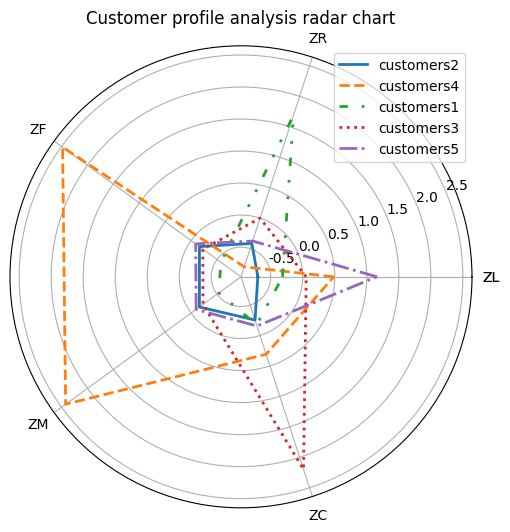

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt 
# 客户分群雷达图
labels = ['ZL','ZR','ZF','ZM','ZC']
# 客户群命名，作为雷达图的图例
legen = ['customers' + str(i + 1) for i in cluster_center.index]
lstype = ['-','--',(0, (3, 5, 1, 5, 1, 5)),':','-.']
kinds = list(cluster_center.iloc[:, 0])
# 由于雷达图要保证数据闭合，因此再添加L列，并转换为 np.ndarray
cluster_center = pd.concat([cluster_center, cluster_center[['ZL']]], axis=1)
centers = np.array(cluster_center.iloc[:, 0:])


# 分割圆周长，并让其闭合
n = len(labels)
angle = np.linspace(0, 2 * np.pi, n, endpoint=False)
angle = np.concatenate((angle, [angle[0]]))

labels = np.concatenate((labels, [labels[0]]))
# 绘图
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111, polar=True)  # 以极坐标的形式绘制图形
# 画线
for i in range(len(kinds)):
    ax.plot(angle, centers[i], linestyle=lstype[i], linewidth=2, label=kinds[i])
# 添加属性标签
ax.set_thetagrids(angle * 180 / np.pi, labels)
plt.title('Customer profile analysis radar chart')
plt.legend(legen)
plt.show()